In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('healthcare_dataset.csv')
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


In [4]:
df.tail()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
55495,eLIZABeTH jaCkSOn,42,Female,O+,Asthma,2020-08-16,Joshua Jarvis,Jones-Thompson,Blue Cross,2650.714952,417,Elective,2020-09-15,Penicillin,Abnormal
55496,KYle pEREz,61,Female,AB-,Obesity,2020-01-23,Taylor Sullivan,Tucker-Moyer,Cigna,31457.797307,316,Elective,2020-02-01,Aspirin,Normal
55497,HEATher WaNG,38,Female,B+,Hypertension,2020-07-13,Joe Jacobs DVM,"and Mahoney Johnson Vasquez,",UnitedHealthcare,27620.764717,347,Urgent,2020-08-10,Ibuprofen,Abnormal
55498,JENniFER JOneS,43,Male,O-,Arthritis,2019-05-25,Kimberly Curry,"Jackson Todd and Castro,",Medicare,32451.092358,321,Elective,2019-05-31,Ibuprofen,Abnormal
55499,jAMES GARCiA,53,Female,O+,Arthritis,2024-04-02,Dennis Warren,Henry Sons and,Aetna,4010.134172,448,Urgent,2024-04-29,Ibuprofen,Abnormal


In [5]:
df.shape

(55500, 15)

In [6]:
df.columns

Index(['Name', 'Age', 'Gender', 'Blood Type', 'Medical Condition',
       'Date of Admission', 'Doctor', 'Hospital', 'Insurance Provider',
       'Billing Amount', 'Room Number', 'Admission Type', 'Discharge Date',
       'Medication', 'Test Results'],
      dtype='object')

In [7]:
df.dtypes

Name                   object
Age                     int64
Gender                 object
Blood Type             object
Medical Condition      object
Date of Admission      object
Doctor                 object
Hospital               object
Insurance Provider     object
Billing Amount        float64
Room Number             int64
Admission Type         object
Discharge Date         object
Medication             object
Test Results           object
dtype: object

In [8]:
df.isnull().sum()

Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Discharge Date        0
Medication            0
Test Results          0
dtype: int64

In [9]:
df.duplicated().sum()       #sum of duplicated rows

np.int64(534)

In [10]:
df.describe() #statistical summary of numeric column

,Age,Billing Amount,Room Number
count,55500.000000,55500.000000,55500.000000
mean,51.539459,25539.316097,301.134829
std,19.602454,14211.454431,115.243069
min,13.000000,-2008.492140,101.000000
25%,35.000000,13241.224652,202.000000
50%,52.000000,25538.069376,302.000000
75%,68.000000,37820.508436,401.000000
max,89.000000,52764.276736,500.000000


# Data Cleaning

In [11]:
df = df.drop_duplicates()

##### 1. Removing Duplicate Rows/Records

In [12]:
df.duplicated().sum()

np.int64(0)

##### 2. Cleaning name Columns

In [13]:
df['Name'] = df['Name'].str.strip().str.title()

In [14]:
df.head(2)

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby Jackson,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,Leslie Terry,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive


##### 3. Fix Negative billing Amounts

In [15]:
df.loc[df['Billing Amount']<0,'Billing Amount'] = df['Billing Amount'].mean()

In [16]:
df.describe()

,Age,Billing Amount,Room Number
count,54966.000000,54966.000000,54966.000000
mean,51.535185,25594.536582,301.124404
std,19.605661,14162.191537,115.223143
min,13.000000,9.238787,101.000000
25%,35.000000,13326.001350,202.000000
50%,52.000000,25544.306284,302.000000
75%,68.000000,37819.858159,401.000000
max,89.000000,52764.276736,500.000000


In [17]:
df['Date of Admission'] = pd.to_datetime(df['Date of Admission'])

In [18]:
df['Discharge Date'] = pd.to_datetime(df['Discharge Date'])

In [19]:
df.dtypes

Name                          object
Age                            int64
Gender                        object
Blood Type                    object
Medical Condition             object
Date of Admission     datetime64[ns]
Doctor                        object
Hospital                      object
Insurance Provider            object
Billing Amount               float64
Room Number                    int64
Admission Type                object
Discharge Date        datetime64[ns]
Medication                    object
Test Results                  object
dtype: object

In [20]:
df['Length_of_stay'] = (df['Discharge Date'] - df['Date of Admission']).dt.days   #adding column

In [21]:
df.head(1)

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Length_of_stay
0,Bobby Jackson,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal,2


 ### Final Cleaning Check

In [22]:
df.isnull().sum()

Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Discharge Date        0
Medication            0
Test Results          0
Length_of_stay        0
dtype: int64

In [23]:
df.shape

(54966, 16)

### Data Analysis and Data Visualization

###### 1. Which medical condition affects the most patients across the network?

In [24]:
condition_count = df['Medical Condition'].value_counts()
condition_count

Medical Condition
Arthritis       9218
Diabetes        9216
Hypertension    9151
Obesity         9146
Cancer          9140
Asthma          9095
Name: count, dtype: int64

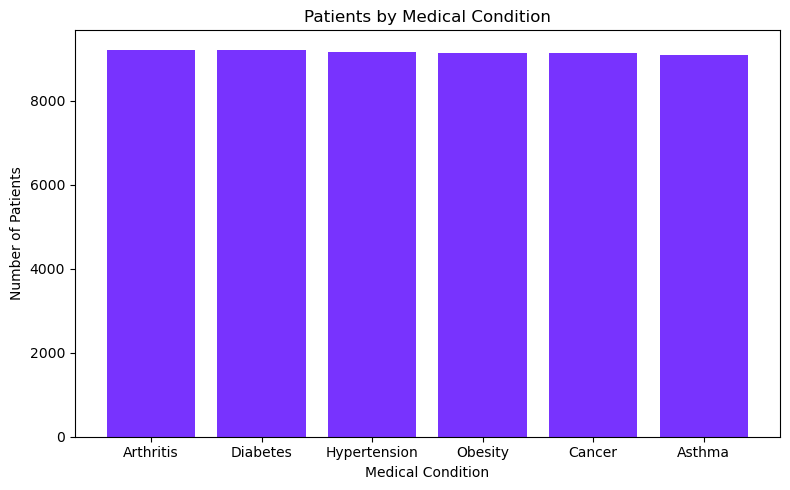

In [25]:
plt.figure(figsize=(8,5))
plt.bar(condition_count.index,condition_count.values,color='#7833FE')
plt.title('Patients by Medical Condition')
plt.xlabel('Medical Condition')
plt.ylabel('Number of Patients')
#plt.xticks(rotation=90)
plt.tight_layout()    #manage spaces between bars
plt.show()

###### 2. How is patient age distributed across the network?


In [26]:
average_age=df['Age'].mean()
average_age

np.float64(51.53518538733035)

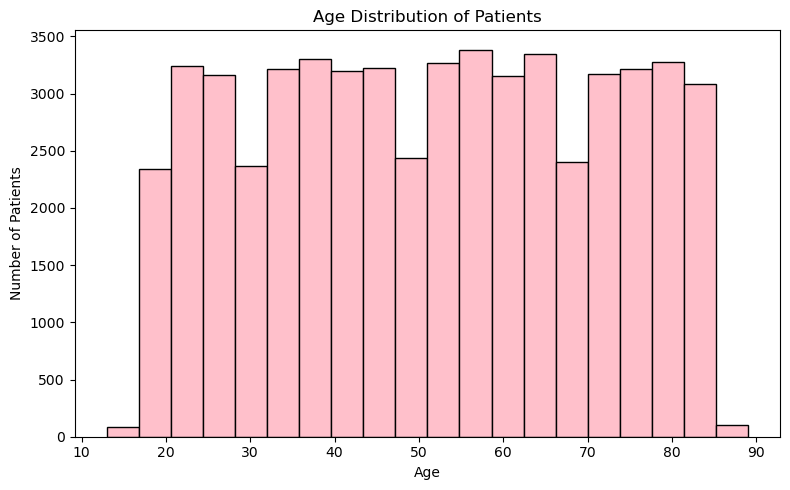

In [27]:
plt.figure(figsize=(8,5))
plt.hist(df['Age'],bins=20,color='Pink',edgecolor='Black')
plt.title('Age Distribution of Patients')
plt.xlabel('Age')
plt.ylabel('Number of Patients')
plt.tight_layout()
plt.show()

###### 3. How has average treatment cost changed over time?

In [28]:
average_cost = df['Billing Amount'].mean()
average_cost

np.float64(25594.536582219524)

In [29]:
df['Admission_month'] = df['Date of Admission'].dt.to_period('M')
monthly_avg_cost = df.groupby('Admission_month')['Billing Amount'].mean()
monthly_avg_cost

Admission_month
2019-05    25897.449655
2019-06    26324.004064
2019-07    25928.602371
2019-08    25457.102225
2019-09    24915.548929
               ...     
2024-01    25836.695757
2024-02    25703.588425
2024-03    25310.583403
2024-04    24930.033214
2024-05    25464.902913
Freq: M, Name: Billing Amount, Length: 61, dtype: float64

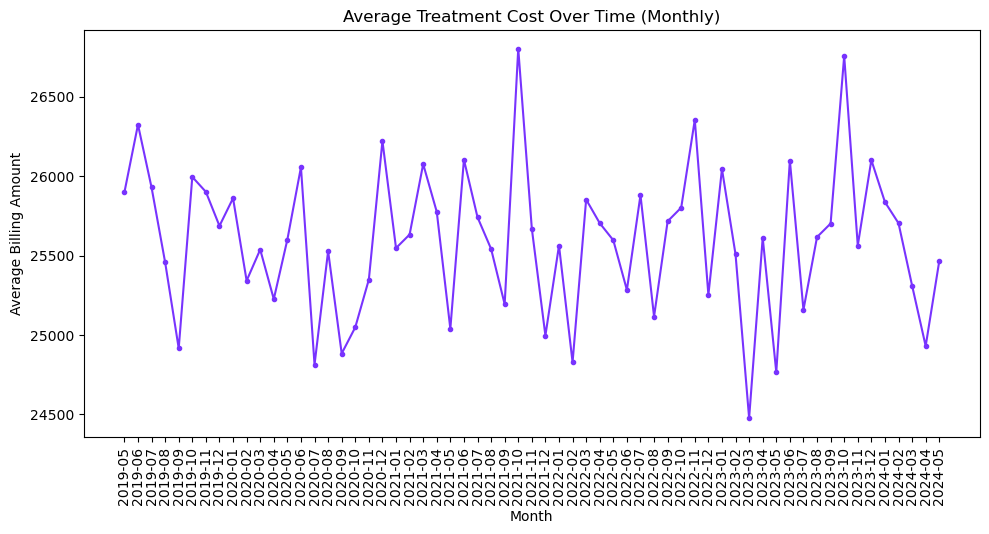

In [30]:
plt.figure(figsize=(10,5))
plt.plot(monthly_avg_cost.index.astype(str),monthly_avg_cost.values,color='#7833FE',marker='o',markersize=3)
plt.title('Average Treatment Cost Over Time (Monthly)')
plt.xlabel('Month')
plt.ylabel('Average Billing Amount')
plt.tight_layout()
plt.xticks(rotation=90)
plt.show()


###### 4. Is there a relationship between patient age and treatment cost ?


In [31]:
senior_avg_cost = df.loc[df['Age']>=60,'Billing Amount'].mean()
senior_avg_cost

np.float64(25563.58776383007)

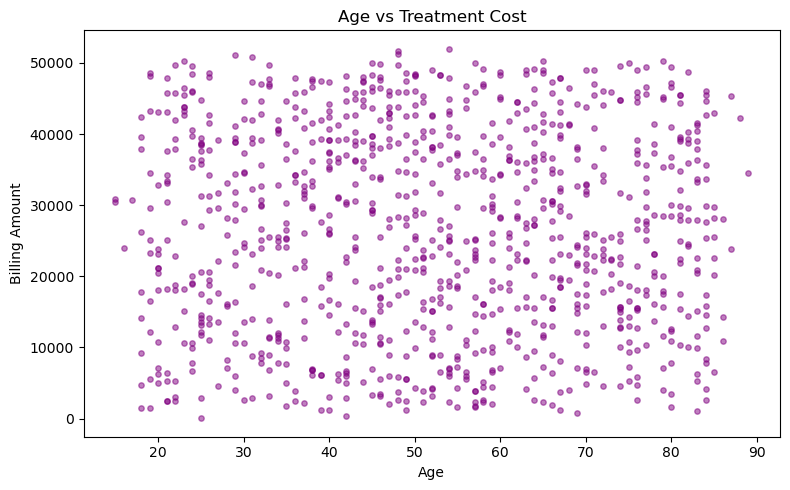

In [32]:
sample_df=df.sample(1000,random_state=1)
plt.figure(figsize=(8,5))
plt.scatter(sample_df['Age'],sample_df['Billing Amount'],color='Purple',alpha=0.5,s=15)
plt.title('Age vs Treatment Cost')
plt.xlabel('Age')
plt.ylabel('Billing Amount')
plt.tight_layout()
plt.show()


###### 5. Which insurance provider covers the most patients ?


In [34]:
insurance_count=df['Insurance Provider'].value_counts()
insurance_count

Insurance Provider
Cigna               11139
Medicare            11039
UnitedHealthcare    11014
Blue Cross          10952
Aetna               10822
Name: count, dtype: int64

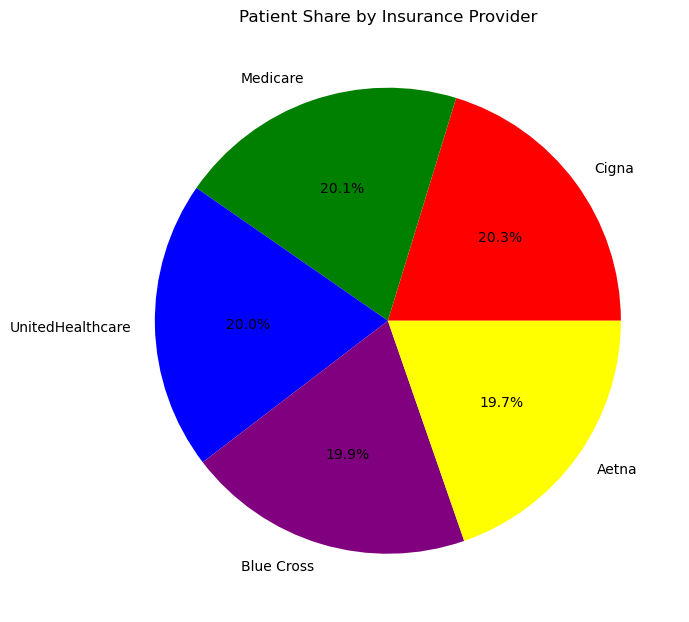

In [35]:
plt.figure(figsize=(7,7))
plt.pie(insurance_count.values,labels=insurance_count.index,autopct='%1.1f%%',colors=['Red','Green','Blue','Purple','Yellow'])
plt.title('Patient Share by Insurance Provider')
plt.tight_layout()
plt.show()

#### AD-HOC QUESTION 1 -- Emergency Department Capacity Planning

###### ***Business Scenario***: "The Hospital management is planning staffing for emergency cases.They want to know how many emergency admissions occurred in each month"

In [37]:
df.dtypes

Name                          object
Age                            int64
Gender                        object
Blood Type                    object
Medical Condition             object
Date of Admission     datetime64[ns]
Doctor                        object
Hospital                      object
Insurance Provider            object
Billing Amount               float64
Room Number                    int64
Admission Type                object
Discharge Date        datetime64[ns]
Medication                    object
Test Results                  object
Length_of_stay                 int64
Admission_month            period[M]
dtype: object

In [38]:
emergency_month = (df.loc[df['Admission Type']=='Emergency'].groupby(df['Date of Admission'].dt.month).size())
emergency_month

Date of Admission
1     1547
2     1452
3     1528
4     1473
5     1533
6     1483
7     1573
8     1533
9     1500
10    1490
11    1462
12    1528
dtype: int64

#### AD-HOC QUESTION 2 - Identify High-Cost Patient Groups

###### ***Business Scenario***: "Hospital finance team wants to identify patients who have unusally high billing amounts so they can review those cases."

In [40]:
high_cost_patients = df.loc[df['Billing Amount']>df['Billing Amount'].quantile(0.90)]
high_cost_patients

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Length_of_stay,Admission_month
5,Emily Johnson,36,Male,A+,Asthma,2023-12-20,Taylor Newton,Nunez-Humphrey,UnitedHealthcare,48145.110951,389,Urgent,2023-12-24,Ibuprofen,Normal,4,2023-12
7,Christina Martinez,20,Female,A+,Cancer,2021-12-28,Suzanne Thomas,"Powell Robinson and Valdez,",Cigna,45820.462722,277,Emergency,2022-01-07,Paracetamol,Inconclusive,10,2021-12
8,Jasmine Aguilar,82,Male,AB+,Asthma,2020-07-01,Daniel Ferguson,Sons Rich and,Cigna,50119.222792,316,Elective,2020-07-14,Aspirin,Abnormal,13,2020-07
30,Thomas Martinez,34,Male,B-,Asthma,2019-08-18,Jacob Huynh,Hart Ltd,Cigna,47909.128810,371,Urgent,2019-09-01,Ibuprofen,Inconclusive,14,2019-08
35,David Anderson,25,Female,AB+,Asthma,2021-01-07,Emma Allison,Sons and Cox,Medicare,45453.418546,228,Elective,2021-01-26,Lipitor,Abnormal,19,2021-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55446,Richard Moore,63,Female,B+,Hypertension,2021-11-17,Dr. Jacob Aguilar,Blevins Group,Aetna,47649.696638,304,Emergency,2021-12-09,Penicillin,Abnormal,22,2021-11
55465,Amanda Stevens,71,Female,O-,Asthma,2019-06-11,Jessica Ramirez,Sims-Henderson,Cigna,45597.476264,164,Urgent,2019-06-22,Ibuprofen,Inconclusive,11,2019-06
55467,Sandra Chen,62,Female,B+,Asthma,2022-06-03,Morgan Hess,Park Ltd,Aetna,48563.608920,269,Emergency,2022-06-06,Lipitor,Abnormal,3,2022-06
55470,Taylor Best,60,Male,A-,Asthma,2020-10-14,Tracy Nichols,"Hopkins and Neal Logan,",Cigna,48664.879041,187,Emergency,2020-10-21,Penicillin,Normal,7,2020-10


#### AD-HOC QUESTION 3 - Flagging Emergency Cases with Abnormal results for review

###### ***Business Scenario***: "Hospital management wants to identify emergency patients whose test results are abnormal,so these cases can be prioritized for review"

In [41]:
priority_cases=df.loc[(df['Admission Type']=='Emergency') & (df['Test Results']=='Abnormal')]
priority_cases.shape[0]

6038

In [44]:
priority_cases

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Length_of_stay,Admission_month
12,Connor Hansen,75,Female,A+,Diabetes,2019-12-12,Kenneth Fletcher,"Powers Miller, and Flores",Cigna,43282.283358,134,Emergency,2019-12-28,Penicillin,Abnormal,16,2019-12
27,Mr. Kenneth Moore,34,Female,A+,Diabetes,2022-06-21,James Ellis,Serrano-Dixon,UnitedHealthcare,18834.801341,157,Emergency,2022-06-30,Lipitor,Abnormal,9,2022-06
38,Nicole Lucero,70,Female,O-,Diabetes,2022-03-12,Christine Johnson,"and Garcia Morris Cunningham,",Cigna,48290.693407,113,Emergency,2022-03-29,Lipitor,Abnormal,17,2022-03
51,Stephanie Kent,42,Female,A-,Cancer,2019-06-15,Mary Moss,Beck-Galloway,Aetna,14681.016360,234,Emergency,2019-07-05,Ibuprofen,Abnormal,20,2019-06
64,Nancy Glover,58,Male,A-,Hypertension,2020-05-08,Jennifer Larson,"Khan, and Rodriguez Fischer",Medicare,19183.168885,378,Emergency,2020-06-01,Aspirin,Abnormal,24,2020-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55471,Ian Murphy,73,Female,B+,Hypertension,2023-05-03,Leslie Guerra,Lozano Ltd,Aetna,28397.377193,348,Emergency,2023-05-06,Lipitor,Abnormal,3,2023-05
55480,Lauren Mills,33,Female,B-,Diabetes,2020-09-30,Mr. David Murray MD,"Riggs, King and Walls",Cigna,22375.523434,323,Emergency,2020-10-26,Aspirin,Abnormal,26,2020-09
55488,Brittney York,43,Female,B-,Obesity,2024-02-02,Richard Matthews,Malone Ltd,Blue Cross,8128.932064,469,Emergency,2024-02-04,Aspirin,Abnormal,2,2024-02
55490,Stephanie Oliver,82,Male,B-,Cancer,2022-01-10,Gary Leblanc,Group Lee,Cigna,17350.543524,381,Emergency,2022-01-21,Penicillin,Abnormal,11,2022-01
